# Shocks Database Exploration

This notebook inspects the raw shock counts database, harmonises key classifications, and summarises event counts across time and geography.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid', context='talk', font_scale=0.9)
MODERN_PALETTE = sns.color_palette('crest')


In [16]:
RAW_PATH = Path('..') / 'data' / 'raw' / 'Shocks_Database_counts.csv'
PANEL_PATH = Path('..') / 'data' / 'full_panel.csv'
OUTPUT_DIR = Path('..') / 'outputs' / 'figures' / 'exploratory'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

raw_df = pd.read_csv(RAW_PATH)
raw_df.head()


,Country name,Year,Shock category,Shock type,count
0,Afghanistan,1971,CLIMATIC,Drought,1
1,Afghanistan,1971,CLIMATIC,Mass movement (wet),1
2,Afghanistan,1972,CLIMATIC,Flood,1
3,Afghanistan,1972,GEOPHYSICAL,Earthquake,1
4,Afghanistan,1973,CONFLICTS,Terrorist attack,1


In [17]:
df = raw_df.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df['shock_category'] = df['shock_category'].str.strip()
df['shock_type'] = df['shock_type'].str.strip()
df.head()


,country_name,year,shock_category,shock_type,count
0,Afghanistan,1971,CLIMATIC,Drought,1
1,Afghanistan,1971,CLIMATIC,Mass movement (wet),1
2,Afghanistan,1972,CLIMATIC,Flood,1
3,Afghanistan,1972,GEOPHYSICAL,Earthquake,1
4,Afghanistan,1973,CONFLICTS,Terrorist attack,1


## Harmonise Shock Categories and Types

In [18]:
def harmonise_classifications(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame['shock_category_lower'] = frame['shock_category'].str.lower()
    frame['shock_type_lower'] = frame['shock_type'].str.lower()

    # Infectious disease shocks sit under ecological in source data; rename type to outbreak for clarity
    mask_ecological_outbreak = (
        frame['shock_category_lower'] == 'ecological'
    ) & (
        frame['shock_type_lower'] == 'infectious disease'
    )
    frame.loc[mask_ecological_outbreak, 'shock_type_lower'] = 'outbreak'
    frame.loc[mask_ecological_outbreak, 'shock_category_lower'] = 'outbreak'

    # Remap type-driven categories for conflict and terrorism
    type_to_category = {
        'interstate conflict': 'interstate',
        'intrastate conflict': 'intrastate',
        'terrorist attack': 'terrorism',
    }
    frame['shock_category_lower'] = frame['shock_category_lower'].where(
        ~frame['shock_type_lower'].isin(type_to_category.keys()),
        frame['shock_type_lower'].map(type_to_category)
    )

    # Build cleaned display columns
    frame['shock_category_clean'] = frame['shock_category_lower'].str.upper()
    frame['shock_type_clean'] = frame['shock_type_lower'].str.title()

    return frame

clean_df = harmonise_classifications(df)
clean_df = clean_df[clean_df['year'] >= 1990].copy()
clean_df[['country_name', 'year', 'shock_category', 'shock_category_clean', 'shock_type', 'shock_type_clean']].head()


,country_name,year,shock_category,shock_category_clean,shock_type,shock_type_clean
33,Afghanistan,1990,CLIMATIC,CLIMATIC,Extreme temperature,Extreme Temperature
34,Afghanistan,1990,CONFLICTS,INTRASTATE,Intrastate conflict,Intrastate Conflict
35,Afghanistan,1990,CONFLICTS,TERRORISM,Terrorist attack,Terrorist Attack
36,Afghanistan,1990,TECHNOLOGICAL,TECHNOLOGICAL,Air,Air
37,Afghanistan,1991,CLIMATIC,CLIMATIC,Extreme temperature,Extreme Temperature


## Attach Continents

In [19]:
panel_df = pd.read_csv(PANEL_PATH, usecols=['Country', 'Continent']).drop_duplicates()
panel_df['Country'] = panel_df['Country'].str.strip()
continent_map = panel_df.set_index('Country')['Continent']

clean_df['country_normalised'] = clean_df['country_name'].str.strip()
clean_df['continent'] = clean_df['country_normalised'].map(continent_map)
missing_continents = clean_df[clean_df['continent'].isna()]['country_normalised'].nunique()
missing_continents


29

In [20]:
missing_names = (
    clean_df[clean_df['continent'].isna()]['country_normalised']
    .drop_duplicates()
    .sort_values()
    .tolist()
)
missing_names[:20], len(missing_names)


(['Armenia',
  'Azerbaijan',
  'Belize',
  'Bosnia and Herzegovina',
  'Brunei Darussalam',
  'Comoros',
  'Croatia',
  'Eswatini',
  'Haiti',
  'Jordan',
  'Kazakhstan',
  'Kuwait',
  'Lesotho',
  'Montenegro',
  'New Zealand',
  'North Korea',
  'North Macedonia',
  'Oman',
  'Paraguay',
  'Poland'],
 29)

In [21]:
clean_df['continent'] = clean_df['continent'].fillna('Unmapped')
clean_df.head()


,country_name,year,shock_category,shock_type,count,shock_category_lower,shock_type_lower,shock_category_clean,shock_type_clean,country_normalised,continent
33,Afghanistan,1990,CLIMATIC,Extreme temperature,1,climatic,extreme temperature,CLIMATIC,Extreme Temperature,Afghanistan,Asia
34,Afghanistan,1990,CONFLICTS,Intrastate conflict,1,intrastate,intrastate conflict,INTRASTATE,Intrastate Conflict,Afghanistan,Asia
35,Afghanistan,1990,CONFLICTS,Terrorist attack,2,terrorism,terrorist attack,TERRORISM,Terrorist Attack,Afghanistan,Asia
36,Afghanistan,1990,TECHNOLOGICAL,Air,2,technological,air,TECHNOLOGICAL,Air,Afghanistan,Asia
37,Afghanistan,1991,CLIMATIC,Extreme temperature,1,climatic,extreme temperature,CLIMATIC,Extreme Temperature,Afghanistan,Asia


In [29]:
clean_df['shock_type_clean'].value_counts()

shock_type_clean
Terrorist Attack                    2239
Flood                               1663
Intrastate Conflict                 1658
Currency Crises                     1503
Outbreak                             933
Storm                                932
Road                                 910
Water                                611
Air                                  473
Earthquake                           409
Extreme Temperature                  360
Banking Crises                       359
Drought                              357
Fire (Miscellaneous)                 306
Mass Movement (Wet)                  296
Rail                                 276
Explosion (Industrial)               249
Wildfire                             204
Debt Crises                          165
Collapse (Miscellaneous)             156
Miscellaneous Accident (General)     145
Explosion (Miscellaneous)            137
Fire (Industrial)                    124
Volcanic Activity                     94

## Descriptive Summaries

In [22]:
summary_overall = (
    clean_df.groupby(['shock_category_clean', 'shock_type_clean'])['count']
    .sum()
    .reset_index()
    .sort_values('count', ascending=False)
)
summary_overall.head(10)


,shock_category_clean,shock_type_clean,count
38,TERRORISM,Terrorist Attack,87573
2,CLIMATIC,Flood,3167
4,CLIMATIC,Storm,2149
36,TECHNOLOGICAL,Road,2117
19,INTRASTATE,Intrastate Conflict,1864
12,ECONOMIC,Currency Crises,1503
20,OUTBREAK,Outbreak,1166
37,TECHNOLOGICAL,Water,978
14,GEOPHYSICAL,Earthquake,642
21,TECHNOLOGICAL,Air,612


In [23]:
category_year = (
    clean_df.groupby(['year', 'shock_category_clean'])['count']
    .sum()
    .reset_index()
)
category_year.head()


,year,shock_category_clean,count
0,1990,CLIMATIC,212
1,1990,ECOLOGICAL,4
2,1990,ECONOMIC,110
3,1990,GEOPHYSICAL,41
4,1990,INTERSTATE,4


### Counts by Category and Year

C:\Users\amahai00\AppData\Local\Temp\ipykernel_10688\1522721462.py:2: UserWarning: 
The palette list has fewer values (6) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


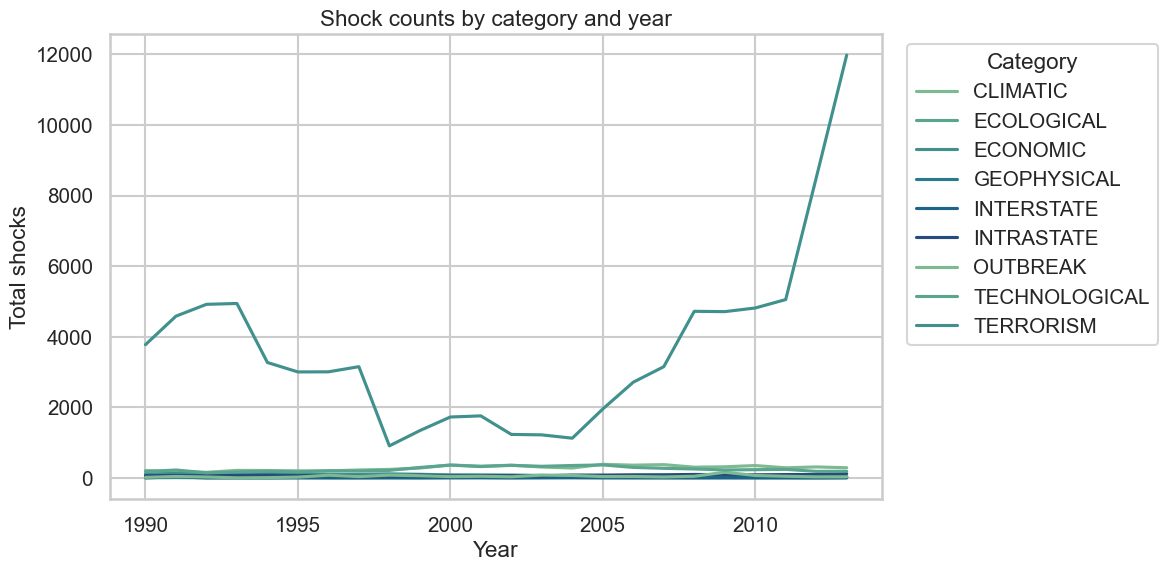

In [24]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=category_year,
    x='year',
    y='count',
    hue='shock_category_clean',
    palette=MODERN_PALETTE,
)
plt.title('Shock counts by category and year')
plt.xlabel('Year')
plt.ylabel('Total shocks')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shock_counts_by_category_year.png', dpi=300)
plt.show()


### Top Categories by Continent

C:\Users\amahai00\AppData\Local\Temp\ipykernel_10688\1071591494.py:7: UserWarning: 
The palette list has fewer values (6) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


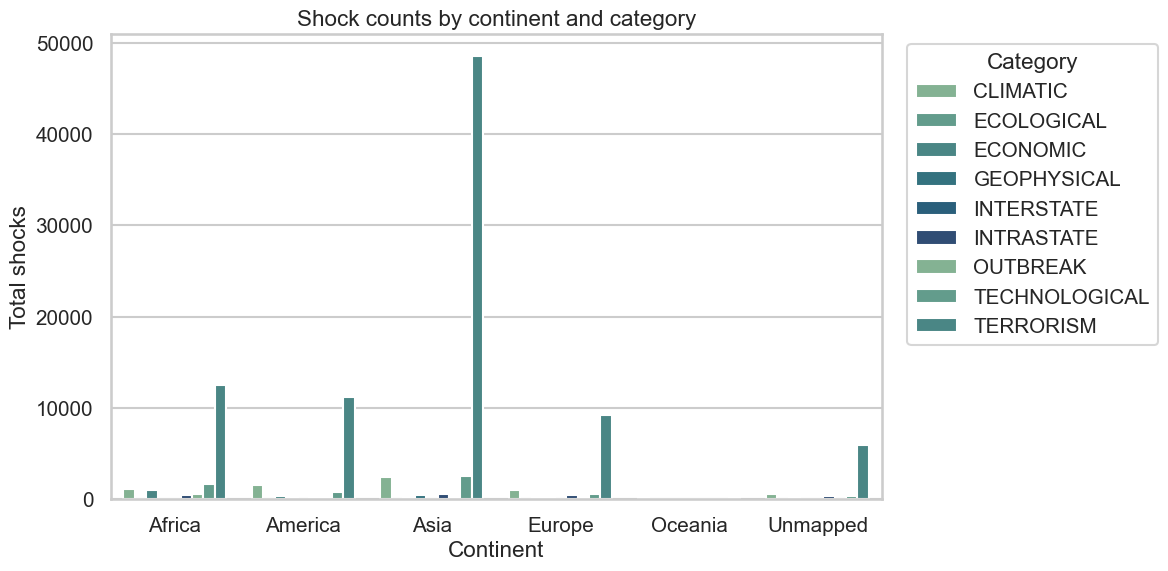

In [25]:
continent_category = (
    clean_df.groupby(['continent', 'shock_category_clean'])['count']
    .sum()
    .reset_index()
)
plt.figure(figsize=(12, 6))
sns.barplot(
    data=continent_category,
    x='continent',
    y='count',
    hue='shock_category_clean',
    palette=MODERN_PALETTE,
)
plt.title('Shock counts by continent and category')
plt.xlabel('Continent')
plt.ylabel('Total shocks')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shock_counts_by_continent_category.png', dpi=300)
plt.show()


### Leading Countries per Category

In [26]:
top_countries = (
    clean_df.groupby(['shock_category_clean', 'country_normalised'])['count']
    .sum()
    .reset_index()
)
idx = top_countries.groupby('shock_category_clean')['count'].idxmax()
top_country_table = top_countries.loc[idx].sort_values('count', ascending=False)
top_country_table


,shock_category_clean,country_normalised,count
1119,TERRORISM,Iraq,12103
909,TECHNOLOGICAL,China,794
159,CLIMATIC,United States,569
628,INTRASTATE,India,112
457,GEOPHYSICAL,China,109
321,ECONOMIC,DR Congo,41
754,OUTBREAK,DR Congo,37
553,INTERSTATE,India,13
247,ECOLOGICAL,North Korea,6


### Heatmap of Category Distribution across Continents

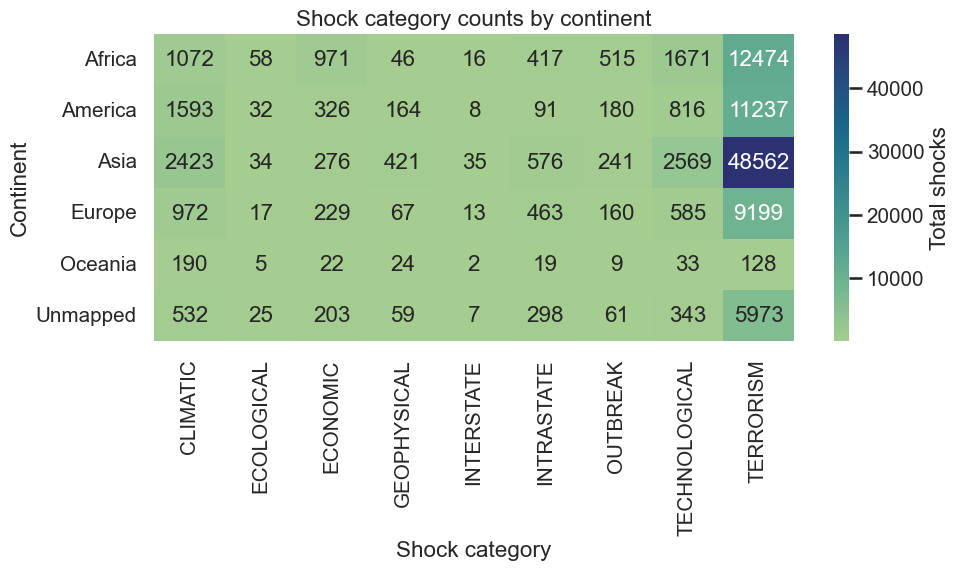

In [27]:
heatmap_data = (
    clean_df.groupby(['continent', 'shock_category_clean'])['count']
    .sum()
    .unstack(fill_value=0)
)
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data,
    cmap='crest',
    annot=True,
    fmt='g',
    cbar_kws={'label': 'Total shocks'}
)
plt.title('Shock category counts by continent')
plt.xlabel('Shock category')
plt.ylabel('Continent')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shock_category_heatmap.png', dpi=300)
plt.show()


## Save Harmonised Dataset

In [28]:
output_path = Path('..') / 'data' / 'processed' / 'shocks_harmonised.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
columns_to_save = [
    'country_name',
    'country_normalised',
    'continent',
    'year',
    'shock_category_clean',
    'shock_type_clean',
    'count',
]
clean_df[columns_to_save].to_csv(output_path, index=False)
output_path


WindowsPath('../data/processed/shocks_harmonised.csv')